In [1]:
import os
import sys
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn_crfsuite

print("sklearn-crfsuite imported successfully.")

sklearn-crfsuite imported successfully.


In [2]:
def load_corpus(filepath):
    """
    Load POS tagged corpus from file.
    Returns list of sentences, where each sentence is a list of (word, tag) tuples.
    """
    sentences = []
    current_sentence = []
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_sentence:
                    sentences.append(current_sentence)
                    current_sentence = []
            else:
                parts = line.split()
                if len(parts) >= 2:
                    current_sentence.append((parts[0], parts[1]))
                elif len(parts) == 1:
                    current_sentence.append((parts[0], 'UNK'))
        if current_sentence:
            sentences.append(current_sentence)
            
    return sentences

# File paths
train_path = 'hindi-train-pos.txt'
dev_path = 'hindi-dev-pos.txt'
test_path = 'hindi-test-pos.txt'

train_sents = load_corpus(train_path)
dev_sents = load_corpus(dev_path)
test_sents = load_corpus(test_path)

all_tags = sorted(list(set(tag for s in train_sents for word, tag in s)))

print(f"Loaded {len(train_sents):,d} train sentences, {len(dev_sents):,d} dev sentences, {len(test_sents):,d} test sentences.")
print(f"Total Unique POS Tags: {len(all_tags)}")

Loaded 15,087 train sentences, 1,866 dev sentences, 1,910 test sentences.
Total Unique POS Tags: 24


In [3]:
def word2features(sent, i):
    """
    Extract feature dictionary for sent[i] according to Assignment 9 requirements.
    """
    word = sent[i][0]
    w_len = len(word)
    
    # 1. Prefixes up to length 4 (Prefix lengths 1, 2, 3, 4)
    # If not found, make that feature = NULL
    p1 = word[:1] if w_len >= 1 else 'NULL'
    p2 = word[:2] if w_len >= 2 else 'NULL'
    p3 = word[:3] if w_len >= 3 else 'NULL'
    p4 = word[:4] if w_len >= 4 else 'NULL'
    
    # 2. Suffixes up to length 4 (Suffix lengths 1, 2, 3, 4)
    # If not found, make that feature = NULL
    s1 = word[-1:] if w_len >= 1 else 'NULL'
    s2 = word[-2:] if w_len >= 2 else 'NULL'
    s3 = word[-3:] if w_len >= 3 else 'NULL'
    s4 = word[-4:] if w_len >= 4 else 'NULL'
    
    # 3. Context Features
    prev_w = sent[i-1][0] if i > 0 else 'BOS'
    next_w = sent[i+1][0] if i < len(sent) - 1 else 'EOS'
    
    # 4. Binary Length Feature: If length <= 4: 'LESS', else 'MORE'
    length_feat = 'LESS' if w_len <= 4 else 'MORE'
    
    features = {
        'bias': 1.0,
        'word': word,
        'prefix_1': p1,
        'prefix_2': p2,
        'prefix_3': p3,
        'prefix_4': p4,
        'suffix_1': s1,
        'suffix_2': s2,
        'suffix_3': s3,
        'suffix_4': s4,
        'prev_word': prev_w,
        'current_word': word,
        'next_word': next_w,
        'length_feature': length_feat
    }
    return features

def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]

def sent2labels(sent):
    return [tag for word, tag in sent]

# Demonstration of extracted features
print("Sample CRF feature dictionary:")
sample_crf_feats = word2features(train_sents[0], 0)
for k, v in sample_crf_feats.items():
    print(f"  {k:15s}: {v}")

Sample CRF feature dictionary:
  bias           : 1.0
  word           : यह
  prefix_1       : य
  prefix_2       : यह
  prefix_3       : NULL
  prefix_4       : NULL
  suffix_1       : ह
  suffix_2       : यह
  suffix_3       : NULL
  suffix_4       : NULL
  prev_word      : BOS
  current_word   : यह
  next_word      : एशिया
  length_feature : LESS


In [4]:
print("Extracting features across all splits...")
t0 = time.time()

X_train = [sent2features(s) for s in train_sents]
y_train = [sent2labels(s) for s in train_sents]

X_dev = [sent2features(s) for s in dev_sents]
y_dev = [sent2labels(s) for s in dev_sents]

X_test = [sent2features(s) for s in test_sents]
y_test = [sent2labels(s) for s in test_sents]

print(f"Feature extraction completed in {time.time() - t0:.2f} s.")

Extracting features across all splits...


Feature extraction completed in 0.50 s.


In [5]:
print("Fitting CRF with L-BFGS optimizer...")
t0 = time.time()

crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True,
    verbose=False
)

crf.fit(X_train, y_train)

crf_train_time = time.time() - t0
print(f"CRF training finished in {crf_train_time:.2f} s ({crf_train_time/60:.2f} minutes).")
print(f"Active labels in CRF: {len(crf.classes_)}")

Fitting CRF with L-BFGS optimizer...


CRF training finished in 40.52 s (0.68 minutes).
Active labels in CRF: 24


In [6]:
def print_top_transitions(trans_features, top_n=10):
    sorted_trans = sorted(trans_features.items(), key=lambda x: x[1], reverse=True)
    print(f"{'Transition':25s} {'Weight':>10s}")
    print("-" * 37)
    for (from_tag, to_tag), weight in sorted_trans[:top_n]:
        print(f"{from_tag + ' -> ' + to_tag:25s} {weight:>10.4f}")
        
    print("\nLeast Likely Transitions:")
    print("-" * 37)
    for (from_tag, to_tag), weight in sorted_trans[-top_n:]:
        print(f"{from_tag + ' -> ' + to_tag:25s} {weight:>10.4f}")

print("=== Top CRF Learned Tag Transitions ===")
print_top_transitions(crf.transition_features_, top_n=8)

=== Top CRF Learned Tag Transitions ===


Transition                    Weight
-------------------------------------
V_VM -> V_VAUX                5.3173
RP_INTF -> QT_QTF             4.0981
N_NNP -> N_NNP                3.9424
RP_INTF -> JJ                 3.6593
V_VAUX -> V_VAUX              3.6223
JJ -> N_NN                    2.8349
RB -> RP_RPD                  2.4703
DM_DMD -> N_NN                2.4253

Least Likely Transitions:
-------------------------------------
JJ -> V_VAUX                 -3.7503
N_NN -> V_VAUX               -3.9211
DM_DMD -> V_VM               -4.2907
RP_NEG -> PSP                -4.4601
QT_QTF -> PSP                -4.4917
JJ -> PSP                    -4.6425
PSP -> V_VAUX                -5.2346
DM_DMD -> PSP                -6.6859


In [7]:
def compute_metrics(y_true, y_pred, tag_list):
    """
    Compute POS evaluation metrics completely from scratch using NumPy and Pandas.
    Calculates Confusion Matrix, Per-tag Precision, Recall, F1, Support,
    Macro F1, Weighted F1, and Overall Accuracy.
    """
    tag2idx = {t: i for i, t in enumerate(tag_list)}
    n_tags = len(tag_list)
    conf_mat = np.zeros((n_tags, n_tags), dtype=np.int64)
    
    for yt, yp in zip(y_true, y_pred):
        if yt in tag2idx and yp in tag2idx:
            conf_mat[tag2idx[yt], tag2idx[yp]] += 1
            
    total_tokens = len(y_true)
    correct_tokens = np.trace(conf_mat)
    accuracy = correct_tokens / total_tokens if total_tokens > 0 else 0.0
    
    per_tag_records = []
    f1_scores = []
    supports = []
    
    for i, tag in enumerate(tag_list):
        tp = conf_mat[i, i]
        fp = np.sum(conf_mat[:, i]) - tp
        fn = np.sum(conf_mat[i, :]) - tp
        support = np.sum(conf_mat[i, :])
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        
        per_tag_records.append({
            'tag': tag,
            'precision': float(precision),
            'recall': float(recall),
            'f1': float(f1),
            'support': int(support)
        })
        if support > 0:
            f1_scores.append(f1)
            supports.append(support)
            
    df_per_tag = pd.DataFrame(per_tag_records)
    macro_f1 = float(np.mean(f1_scores)) if f1_scores else 0.0
    weighted_f1 = float(np.sum(np.array(f1_scores) * np.array(supports)) / np.sum(supports)) if np.sum(supports) > 0 else 0.0
    
    summary = {
        'accuracy': float(accuracy),
        'macro_f1': float(macro_f1),
        'weighted_f1': float(weighted_f1),
        'total_tokens': int(total_tokens)
    }
    return summary, df_per_tag

print("Metrics function verified.")

Metrics function verified.


In [8]:
print("Evaluating CRF on Development set...")
t0 = time.time()
y_dev_pred_nested = crf.predict(X_dev)
dev_pred_time = time.time() - t0

# Flatten lists
y_dev_true_flat = [tag for s in y_dev for tag in s]
y_dev_pred_flat = [tag for s in y_dev_pred_nested for tag in s]

dev_summary, dev_tag_df = compute_metrics(y_dev_true_flat, y_dev_pred_flat, all_tags)
dev_tag_df['split'] = 'dev'
dev_tag_df['model'] = 'CRF'

print(f"Decoded {len(y_dev_true_flat):,d} dev tokens in {dev_pred_time:.2f} s")
print(f"CRF Dev Accuracy    : {dev_summary['accuracy']*100:.2f}%")
print(f"CRF Dev Macro F1    : {dev_summary['macro_f1']*100:.2f}%")
print(f"CRF Dev Weighted F1 : {dev_summary['weighted_f1']*100:.2f}%")

print("\n--- Top 10 Tags by Support on Dev Set ---")
print(dev_tag_df.sort_values(by='support', ascending=False).head(10)[['tag', 'precision', 'recall', 'f1', 'support']].to_string(index=False))

Evaluating CRF on Development set...


Decoded 40,762 dev tokens in 0.20 s
CRF Dev Accuracy    : 96.40%
CRF Dev Macro F1    : 96.53%
CRF Dev Weighted F1 : 96.39%

--- Top 10 Tags by Support on Dev Set ---


    tag  precision   recall       f1  support
   N_NN   0.930916 0.953836 0.942237     9098
    PSP   0.997260 0.998130 0.997695     8023
  N_NNP   0.910352 0.878838 0.894317     4853
   V_VM   0.987500 0.984482 0.985988     4253
 V_VAUX   0.990555 0.989387 0.989971     2544
RD_PUNC   1.000000 1.000000 1.000000     2487
     JJ   0.935622 0.919831 0.927660     2370
 PR_PRP   0.985138 0.974790 0.979937     1428
 QT_QTC   0.970964 0.976636 0.973791      856
 CC_CCD   0.985612 0.991556 0.988575      829


In [9]:
print("Evaluating CRF on Test set...")
t0 = time.time()
y_test_pred_nested = crf.predict(X_test)
test_pred_time = time.time() - t0

# Flatten lists
y_test_true_flat = [tag for s in y_test for tag in s]
y_test_pred_flat = [tag for s in y_test_pred_nested for tag in s]

test_summary, test_tag_df = compute_metrics(y_test_true_flat, y_test_pred_flat, all_tags)
test_tag_df['split'] = 'test'
test_tag_df['model'] = 'CRF'

print(f"Decoded {len(y_test_true_flat):,d} test tokens in {test_pred_time:.2f} s")
print(f"CRF Test Accuracy    : {test_summary['accuracy']*100:.2f}%")
print(f"CRF Test Macro F1    : {test_summary['macro_f1']*100:.2f}%")
print(f"CRF Test Weighted F1 : {test_summary['weighted_f1']*100:.2f}%")

print("\n--- Top 10 Tags by Support on Test Set ---")
print(test_tag_df.sort_values(by='support', ascending=False).head(10)[['tag', 'precision', 'recall', 'f1', 'support']].to_string(index=False))

Evaluating CRF on Test set...


Decoded 41,415 test tokens in 0.20 s
CRF Test Accuracy    : 96.49%
CRF Test Macro F1    : 92.90%
CRF Test Weighted F1 : 96.49%

--- Top 10 Tags by Support on Test Set ---
    tag  precision   recall       f1  support
   N_NN   0.935733 0.950016 0.942821     9303
    PSP   0.995638 0.996604 0.996121     8245
  N_NNP   0.916020 0.891805 0.903750     5296
   V_VM   0.987293 0.986584 0.986938     4174
RD_PUNC   0.999608 1.000000 0.999804     2549
 V_VAUX   0.989011 0.994475 0.991736     2534
     JJ   0.924396 0.931355 0.927862     2258
 PR_PRP   0.988671 0.978326 0.983471     1338
 QT_QTC   0.979191 0.969108 0.974123      874
 CC_CCD   0.982051 0.992228 0.987113      772


In [10]:
crf_summary_df = pd.DataFrame([
    {
        'split': 'dev',
        'model': 'CRF',
        'accuracy': dev_summary['accuracy'],
        'macro_f1': dev_summary['macro_f1'],
        'weighted_f1': dev_summary['weighted_f1'],
        'total_tokens': dev_summary['total_tokens']
    },
    {
        'split': 'test',
        'model': 'CRF',
        'accuracy': test_summary['accuracy'],
        'macro_f1': test_summary['macro_f1'],
        'weighted_f1': test_summary['weighted_f1'],
        'total_tokens': test_summary['total_tokens']
    }
])

crf_summary_df.to_csv('crf_summary_metrics.csv', index=False)
print("Saved crf_summary_metrics.csv:")
print(crf_summary_df.to_string(index=False))

crf_all_tag_df = pd.concat([dev_tag_df, test_tag_df], ignore_index=True)
crf_all_tag_df.to_csv('crf_per_tag_results.csv', index=False)
print(f"\nSaved crf_per_tag_results.csv ({len(crf_all_tag_df)} rows).")

Saved crf_summary_metrics.csv:
split model  accuracy  macro_f1  weighted_f1  total_tokens
  dev   CRF  0.963986  0.965342     0.963876         40762
 test   CRF  0.964940  0.929043     0.964851         41415

Saved crf_per_tag_results.csv (48 rows).


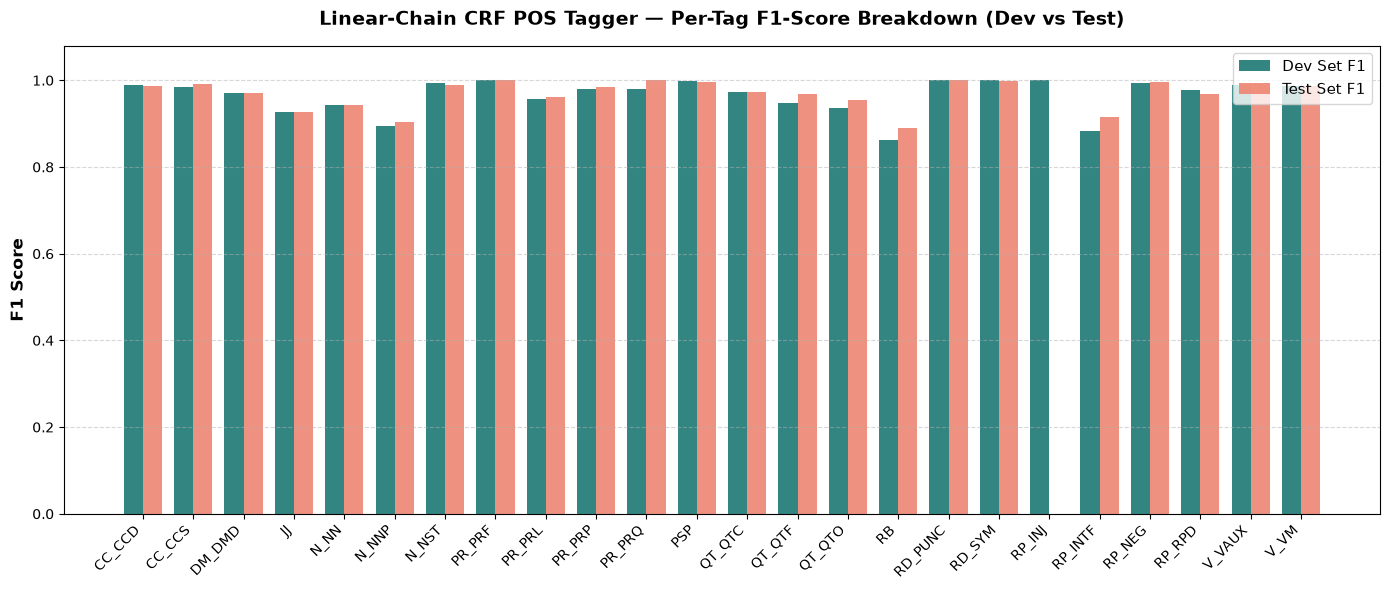

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(all_tags))
width = 0.38

dev_f1s = [dev_tag_df.loc[dev_tag_df['tag'] == t, 'f1'].values[0] if t in dev_tag_df['tag'].values else 0 for t in all_tags]
test_f1s = [test_tag_df.loc[test_tag_df['tag'] == t, 'f1'].values[0] if t in test_tag_df['tag'].values else 0 for t in all_tags]

rects1 = ax.bar(x - width/2, dev_f1s, width, label='Dev Set F1', color='#1d7874', alpha=0.9)
rects2 = ax.bar(x + width/2, test_f1s, width, label='Test Set F1', color='#ee8572', alpha=0.9)

ax.set_ylabel('F1 Score', fontsize=12, fontweight='bold')
ax.set_title('Linear-Chain CRF POS Tagger — Per-Tag F1-Score Breakdown (Dev vs Test)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(all_tags, rotation=45, ha='right', fontsize=10)
ax.set_ylim(0, 1.08)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(frameon=True, fontsize=11)

plt.tight_layout()
plt.savefig('crf_per_tag_f1.png', dpi=300)
plt.show()